
# Lab Corner Detection


## Goal of this lab

In this lab we will take our knowledge on convolution and filtering for implementing the Harris Corner Detector. The Harris Corner detector can be implemented by a series of convolution operations as follows (see also the lecture slides for a visualization of the approach).

Required packages

* numpy
* matplotlib
* scipy
* scikit-image
* skimage
* imageio

You can execute individual code blocks by pressing SHIFT+Enter consecutively.

You can trigger auto completion with TABULATOR


## Import required packages

In [1]:
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt
from scipy import signal
import imageio.v2 as imageio
from skimage import color
from skimage import feature

## Provided Functions

In [2]:
def gauss2D(shape=(3,3),sigma=0.5):
    #src: https://stackoverflow.com/questions/17190649/how-to-obtain-a-gaussian-filter-in-python
    m,n = [(ss-1.)/2. for ss in shape]
    y,x = np.ogrid[-m:m+1,-n:n+1]
    h = np.exp( -(x*x + y*y) / (2.*sigma*sigma) )
    h[ h < np.finfo(h.dtype).eps*h.max() ] = 0
    sumh = h.sum()
    if sumh != 0:
        h /= sumh
    return h

## Exercise 1: Sobel operator

1. Load the image harris.jpg with *imageio.imread()*, check the shape of the image and if necessary convert the image into a grayscale image by using *color.rgb2gray()*. Normalize the values to the range 0..1, i.e. divide by the maximum value.
2. Define a 3x3 Sobel filter (https://de.wikipedia.org/wiki/Sobel-Operator) for vertical and horizontal edges (call them Gx and Gy). We use these filters to extract estimates for the gradients, i.e. the edges. 
3. Convolve the image with both filters. Store the results in Ix and Iy. Plot the results.
4. Compute the square of Ix amd Iy as well as the product of Ix and Iy and store the result in Ix2, Iy2 and Ixy. Plot the results.
5. Define a 2D Gaussian filter of size 12x12 and sigma 2 (use the provided function)
6. Convolve Ix2, Iy2 and Ixy with the Gaussian filter (to smooth out any noise). To store the results, reuse the respective variable names. Plot the results.

To plot the input image and the filtered result image use the following code (im_in and im_out are the input and output images):
~~~python
SIZE = 20;
f, (ax1, ax2) = plt.subplots(1, 2,figsize=(SIZE,5*SIZE))
ax1.imshow(im_in,cmap='gray') 
ax1.set_title('Input')
ax1.axis('off')
ax2.imshow(im_out,cmap='gray') 
ax2.set_title('Output')
ax2.axis('off')
plt.show()
~~~

Shape: (200, 256)


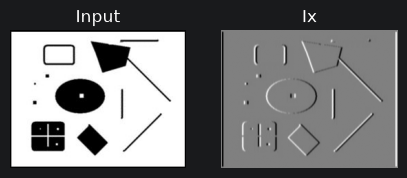

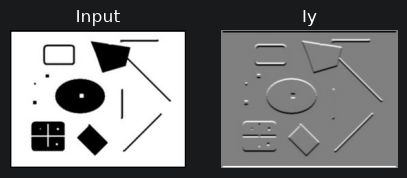

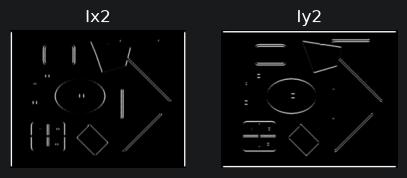

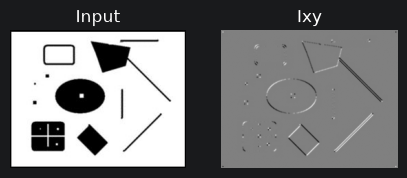

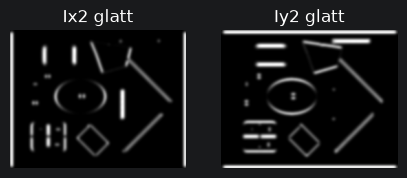

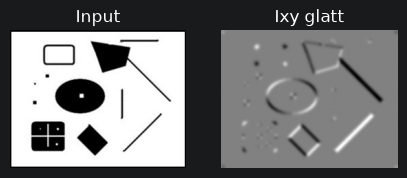

In [3]:
# 1.
im = imageio.imread('../../data/test_images/harris.jpg').astype('float32')
print('Shape:', im.shape)
if im.ndim == 3:
    im = color.rgb2gray(im)
im = im / im.max()

# 2.
Gx = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]], dtype='float32')
Gy = np.transpose(Gx)

# 3.
Ix = signal.convolve2d(im, Gx, mode='same', boundary='fill', fillvalue=0)
Iy = signal.convolve2d(im, Gy, mode='same', boundary='fill', fillvalue=0)

SIZE = 5
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(im, cmap='gray'); ax1.set_title('Input'); ax1.axis('off')
ax2.imshow(Ix, cmap='gray'); ax2.set_title('Ix'); ax2.axis('off')
plt.show()

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(im, cmap='gray'); ax1.set_title('Input'); ax1.axis('off')
ax2.imshow(Iy, cmap='gray'); ax2.set_title('Iy'); ax2.axis('off')
plt.show()

# 4.
Ix2 = Ix ** 2
Iy2 = Iy ** 2
Ixy = Ix * Iy

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(Ix2, cmap='gray'); ax1.set_title('Ix2'); ax1.axis('off')
ax2.imshow(Iy2, cmap='gray'); ax2.set_title('Iy2'); ax2.axis('off')
plt.show()

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(im,  cmap='gray'); ax1.set_title('Input'); ax1.axis('off')
ax2.imshow(Ixy, cmap='gray'); ax2.set_title('Ixy');   ax2.axis('off')
plt.show()

# 5.
gauss = gauss2D(shape=(12, 12), sigma=2)

# 6.
Ix2 = signal.convolve2d(Ix2, gauss, mode='same', boundary='fill', fillvalue=0)
Iy2 = signal.convolve2d(Iy2, gauss, mode='same', boundary='fill', fillvalue=0)
Ixy = signal.convolve2d(Ixy, gauss, mode='same', boundary='fill', fillvalue=0)

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(Ix2, cmap='gray'); ax1.set_title('Ix2 glatt'); ax1.axis('off')
ax2.imshow(Iy2, cmap='gray'); ax2.set_title('Iy2 glatt'); ax2.axis('off')
plt.show()

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(im,  cmap='gray'); ax1.set_title('Input');     ax1.axis('off')
ax2.imshow(Ixy, cmap='gray'); ax2.set_title('Ixy glatt'); ax2.axis('off')
plt.show()

## Exercise 2: Your Harris Corner Detector
1. Compute the "Cornerness-Function" R for each pixel, as defined in the lecture slides. Compute R directly from Ix2, Iy2 and Ixy. This can all be done in a vectorized manner (no loops are needed). The result is an image R that contains at each pixel the value r for the respective pixel. Plot the resulting image R. Hint: use 0.04 for parameter K in the equation of R from the lecture slides.
2. To get the corner positions, extract the peaks of image R. Therefore, loop over all pixels (with two for loops) and check for every pixel, if it is higher than its 8 neighbors. For a pixel at position [x,y] these neighbors are: [x-1,y-1],[x-1,y],[x-1,y+1],[x,y-1],[x,y+1],[x+1,y-1],[x+1,y] and [x+1,y+1]. Use zero-padding to be able to compute values for the border pixels. Additionally make sure that the peak has a certain height, i.e. assure that it is higher than max(R)*0.01. For all pixels, where the above conditions meet, get the location (x and y) and store them in a list or a numpy array. Plot the original image and visualize the detected corners from that list/array on top of the image.

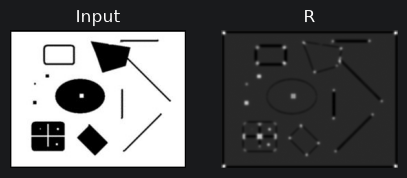

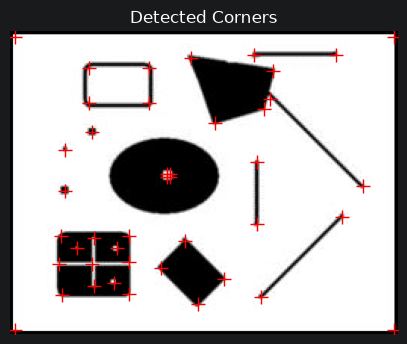

In [4]:
# 1.
K = 0.04
det_M = Ix2 * Iy2 - Ixy ** 2
trace_M = Ix2 + Iy2
R = det_M - K * (trace_M ** 2)

SIZE = 5
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE, SIZE))
ax1.imshow(im, cmap='gray'); ax1.set_title('Input'); ax1.axis('off')
ax2.imshow(R,  cmap='gray'); ax2.set_title('R');     ax2.axis('off')
plt.show()

# 2.
R_padded = np.pad(R, 1, mode='constant', constant_values=0)
threshold = R.max() * 0.01
corners = []

for x in range(R.shape[0]):
    for y in range(R.shape[1]):
        val = R_padded[x+1, y+1]
        neighborhood = R_padded[x:x+3, y:y+3].flatten()
        neighborhood = np.delete(neighborhood, 4)  # Center entfernen
        if val > threshold and val > neighborhood.max():
            corners.append((y, x))

corners = np.array(corners)

f, ax = plt.subplots(1, 1, figsize=(SIZE, SIZE))
ax.imshow(im, cmap='gray')
ax.plot(corners[:, 0], corners[:, 1], 'r+', markersize=10, markeredgewidth=1)
ax.set_title('Detected Corners'); ax.axis('off')
plt.show()

## Exercise 3: Harris Corner Detector Comparison

1. Try out your Harris Corner Detector with an arbitrary image.
2. Compare the results with that of the Harris Corner Detector from scikit-image (http://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.corner_harris)! Use the functions *corner_harris* and *corner_peaks*.


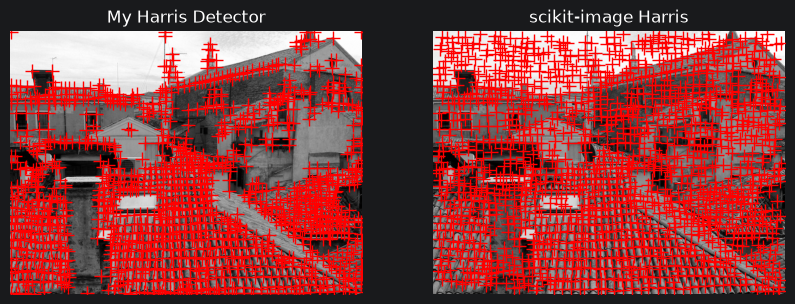

In [5]:
# 1.
im2 = imageio.imread('../../data/test_images/roofs1.jpg').astype('float32')
if im2.ndim == 3:
    im2 = color.rgb2gray(im2)
im2 = im2 / im2.max()

Ix = signal.convolve2d(im2, Gx, mode='same', boundary='fill', fillvalue=0)
Iy = signal.convolve2d(im2, Gy, mode='same', boundary='fill', fillvalue=0)
Ix2 = signal.convolve2d(Ix ** 2, gauss, mode='same', boundary='fill', fillvalue=0)
Iy2 = signal.convolve2d(Iy ** 2, gauss, mode='same', boundary='fill', fillvalue=0)
Ixy = signal.convolve2d(Ix * Iy, gauss, mode='same', boundary='fill', fillvalue=0)

R2 = Ix2 * Iy2 - Ixy ** 2 - K * ((Ix2 + Iy2) ** 2)

R2_padded = np.pad(R2, 1, mode='constant', constant_values=0)
threshold2 = R2.max() * 0.01
corners2 = []
for x in range(R2.shape[0]):
    for y in range(R2.shape[1]):
        val = R2_padded[x+1, y+1]
        neighborhood = R2_padded[x:x+3, y:y+3].flatten()
        neighborhood = np.delete(neighborhood, 4)
        if val > threshold2 and val > neighborhood.max():
            corners2.append((y, x))
corners2 = np.array(corners2)

# 2.
R_skimage = feature.corner_harris(im2)
corners_skimage = feature.corner_peaks(R_skimage, min_distance=5)

SIZE = 5
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(SIZE*2, SIZE))
ax1.imshow(im2, cmap='gray')
ax1.plot(corners2[:, 0], corners2[:, 1], 'r+', markersize=10, markeredgewidth=1)
ax1.set_title('My Harris Detector'); ax1.axis('off')
ax2.imshow(im2, cmap='gray')
ax2.plot(corners_skimage[:, 1], corners_skimage[:, 0], 'r+', markersize=10, markeredgewidth=1)
ax2.set_title('scikit-image Harris'); ax2.axis('off')
plt.show()